# 实验说明
本实验的主要内容为：在CIFAR-10数据集上训练一个神经网络，了解训练和推理（预测）的基本流程、探究神经网络的设计（包括网络结构、超参数）对模型性能的影响。
> CIFAR-10数据集，又称加拿大高等研究院数据集（Canadian Institute for Advanced Research）是一个常用于训练机器学习和计算机视觉算法的图像集合。它是最广泛使用的机器学习研究数据集之一。CIFAR-10数据集包含60,000张32×32像素的彩色图像，分为10个不同的类别。这10个类别分别是飞机、汽车、鸟类、猫、鹿、狗、青蛙、马、船和卡车，每个类别有6,000张图片。——维基百科

在进行实验前，最好对以下内容有所了解：
- 基础的Python语法；
- 机器学习领域的基本概念与基础的数学知识（参见[动手学深度学习](https://zh.d2l.ai/index.html)1-3章）；
- 神经网络的基本概念（如全连接层、卷积层、池化层，参见[动手学深度学习](https://zh.d2l.ai/index.html)4-6章）。

# 实验要求
实验基础代码已经在下面给出。你需要保证自己在熟悉了基础代码后，在Task1~Task4中选择至少3个完成。
- 提交内容：源代码、实验报告、模型权重文件
- 报告要求：提交pdf版本实验报告，包括摘要、引言、方法、实验以及总结部分，4页左右。如果你在探索中有任何其它发现或想法，也请加入到报告中。
# 实验报告说明
0. **摘要（Abstract）**：引⾔的⼀个⾼度浓缩版本，通过⼀段话介绍你研究的所有内容。
1. **引⾔（Introduction）**：这是摘要的⼀个扩写版本，包含更多⼀些的细节。通过⼏段话（2-3段）总结整个报告的内容，让读者通过阅读引⾔就可以知道你做的具体内容。⼀般包括：要解决的问题、⽬标、相关技术背景、你的实验思路和主要实验结论。
2. **方法（Methodology）**：介绍你具体的实验思路，详细定义研究问题，详细描述实验⽅法，要求简单、精炼、准确。有必要的话需要给出具体的算法。
3. **实验（Experiments）**：包括实验设置（Experimental Setup）和实验结果（Main Results）两个部分。其中，实验设置介绍模型、数据集、超参数设置等；实验结果以图、表的形式介绍每组实验的结果和发现。
4. **总结（Conclusion）**：以简短的⼀段话总结整个报告。
# 实验基础代码
机器学习可大致分为三个部分：数据、模型以及算法。下面，我们按照这一顺序给出实验的基础代码。

# 实验分数说明
共四个子任务，每个3分，实验报告8分

# 0. 导入必要的库

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.transforms import ToPILImage
show = ToPILImage()

# 1. 准备训练数据与测试数据
首先我们介绍数据部分。`torchvision`库已经为我们直接提供了CIFAR-10数据集的下载，我们就不需要手动地去网上下载了。代码中的`transform`将原始的图像转换为模型易于处理的形式。`trainloader`和`testloader`分别用于加载训练集和测试集。

In [2]:
# 设定对图片的归一化处理方式，并且下载数据集
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
     ])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./dataset', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./dataset', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)


100.0%


Extracting ./dataset/cifar-10-python.tar.gz to ./dataset
Files already downloaded and verified


通过运行下面的代码，可得知CIFAR-10数据集的训练集包含50000张图像，每张图像的大小为32*32；数据集中的每个元素是由数据和对应的标签组成的。

In [3]:
# 观察一下数据集的内容
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck') # 类别名称
print(len(trainset)) # 训练集大小
print(trainset[0][0].size()) # 第 1 条数据的图像大小
print(trainset[0][1]) # 第 1 条数据的标签
print(classes[trainset[0][1]]) # 第 1 条数据的文本标签

50000
torch.Size([3, 32, 32])
6
frog


下面这段代码在训练集中随意抽出一张进行可视化，注意在展示之前我们需要将其做上述`transform`的逆变换：

torch.Size([3, 32, 32])
7
horse


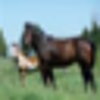

In [4]:
# 1 - 4行与上一块代码意义类似
(data, label) = trainset[12] # 选群训练集的一个样本展示内容，也可以改成其他数字看看
print(data.size()) 
print(label) # label是整数
print(classes[label])
show((data + 1) / 2).resize((100, 100)) # 还原被归一化的图片

# 2. 定义用于分类的网络结构

这一部分我们定义用于图像分类的网络结构，实现一个早期的卷积神经网络LeNet。它由两个卷积层和三个全连接层组成。pytorch为我们提供了方便的接口定义神经网络，但我们这里不着重介绍具体的语法，只观察数据是怎样在模型中“流动”的：
- 在`__init__`方法中，我们将上述的卷积层和全连接层初始化为`conv1、conv2`和`fc1、fc2、fc3`；
- 卷积层以`conv1`为例，它的初始化为`Conv2d(3, 6, 5)`，即：3输入通道（RGB图像的三个通道）、6输出通道、5*5大小的卷积核的卷积层。
- 全连接层以`fc1`为例，它的初始化为`Linear(16 * 5 * 5, 120)`，即：从400维映射到120维。
- `forward`方法用于规定数据在模型中的计算过程。输入的形状在传播过程中的变化参见`forward`中的注释。最终，我们得到了一个大小为`[batch size, 10]`的张量（矩阵）。

In [5]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        # nn.Module子类的函数必须在构造函数中执行父类的构造函数
        super(Net, self).__init__()

        # 卷积层 '3'表示输入图片为单通道, '6'表示输出通道数，'5'表示卷积核为5*5
        self.conv1 = nn.Conv2d(3, 6, 5) 
        # 卷积层
        self.conv2 = nn.Conv2d(6, 16, 5) 
        # 仿射层/全连接层，y = Wx + b
        self.fc1 = nn.Linear(16*5*5, 120) 
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x): 
        # 卷积 -> 激活 -> 池化 (relu激活函数不改变输入的形状)
        # [batch size, 3, 32, 32] -- conv1 --> [batch size, 6, 28, 28] -- maxpool --> [batch size, 6, 14, 14]
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2))
        # [batch size, 6, 14, 14] -- conv2 --> [batch size, 16, 10, 10] --> maxpool --> [batch size, 16, 5, 5]
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        # 把 16 * 5 * 5 的特征图展平，变为 [batch size, 16 * 5 * 5]，以送入全连接层
        x = x.view(x.size()[0], -1) 
        # [batch size, 16 * 5 * 5] -- fc1 --> [batch size, 120]
        x = F.relu(self.fc1(x))
        # [batch size, 120] -- fc2 --> [batch size, 84]
        x = F.relu(self.fc2(x))
        # [batch size, 84] -- fc3 --> [batch size, 10]
        x = self.fc3(x)        
        return x

net = Net()
print(net)

Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


# 3. 模型训练与测试过程
准备好数据、定义好模型后，我们开始训练过程。为了把一个随机初始化的模型优化成一个“好”的模型，我们还需要定义：
- 损失函数$\mathcal{L}$：损失函数以一般同时以模型的预测$\hat{y}$和真实的标签$y$为输入，输出一个标量。这个标量越小，说明模型在数据上拟合得越好。我们的目的就是要最小化这个损失函数$\mathcal{L}(\hat{y},y).$分类问题常使用交叉熵函数作为损失函数。
- 优化方法：为了最小化损失函数，我们就要使用数学的优化方法找到一组最优的参数（这里的参数即神经网络中卷积层、全连接层等的参数，而非batch size等超参数）。深度学习中一般使用迭代的方式求解，常用的方法有SGD（随机梯度下降）、Adam等。
pytorch库内置了各种优化器，我们无需手动实现梯度下降过程。

In [6]:
from torch import optim
criterion = nn.CrossEntropyLoss() # 交叉熵损失函数
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9) # 使用SGD（随机梯度下降）优化
num_epochs = 5 # 训练 5 个 epoch

下面我们定义用于训练过程的代码。最外层循环控制在整个数据集上训练的次数（即epoch）；内层循环按照以下流程进行：
1. 取出数据（一次取出一个batch）；
2. 将数据送入网络，计算损失函数；
3. 使用损失函数计算梯度，进行反向传播更新参数。

In [7]:
count = [] # Epoch数
losses = [] # Loss值
def train(trainloader, net, num_epochs, criterion, optimizer, save_path):
    for epoch in range(num_epochs):     
        running_loss = 0.0
        for i, data in enumerate(trainloader, 0):
    
            # 1. 取出数据
            inputs, labels = data
    
            # 梯度清零
            optimizer.zero_grad()
    
            # 2. 前向计算和反向传播
            outputs = net(inputs) # 送入网络（正向传播）
            loss = criterion(outputs, labels) # 计算损失函数
            
            # 3. 反向传播，更新参数
            loss.backward() # 反向传播
            optimizer.step()

            # 下面的这段代码对于训练无实际作用，仅用于观察训练状态
            running_loss += loss.item()
        print('epoch %d: batch %5d loss: %.3f' % (epoch + 1, 12500, running_loss / 12500))
        count.append(epoch + 1) # 记录Epoch数
        losses.append(running_loss / 12500) # 每1个epoch记录一下训练状态
        running_loss = 0.0
            
        torch.save(net.state_dict(), f"{save_path}/epoch_{epoch + 1}_model.pth")
        
    print('Finished Training')

In [8]:
# 使用定义的网络进行训练
save_path = './save_path'
train(trainloader, net, num_epochs, criterion, optimizer, save_path)

epoch 1: batch 12500 loss: 1.706
epoch 2: batch 12500 loss: 1.333
epoch 3: batch 12500 loss: 1.196
epoch 4: batch 12500 loss: 1.109
epoch 5: batch 12500 loss: 1.040
Finished Training


训练过程结束后，我们得到了一个在训练集上拟合较好的模型。下面我们要测试它在测试集上表现如何。预测的代码与训练中的正向传播类似，但是不需要计算损失函数（损失函数在实验中仅用于更新参数，预测时参数固定，也就不需要它了）。

预测的流程如下：
1. 取出数据；
2. 正向传播，得到模型的输出结果；
3. 从输出结果中得到模型预测；
4. 和真实标签进行比对，计算性能指标。

注意：模型的输出结果在第2部分中已经说明，为一个`[batch size, 10]`大小的张量（矩阵），每一行是一条数据属于10个类别的概率的相对大小（这一输出也被称为`logits`）。为了得到模型的预测，我们需要对这一输出在每行上取最大值，取得最大值的**位置**就是模型的预测。

In [9]:
def predict(testloader, net):
    correct = 0 # 预测正确的图片数
    total = 0 # 总共的图片数
    
    with torch.no_grad(): # 正向传播时不计算梯度
        for data in testloader:
            # 1. 取出数据
            images, labels = data
            # 2. 正向传播，得到输出结果
            outputs = net(images)
            # 3. 从输出中得到模型预测
            _, predicted = torch.max(outputs, 1)
            # 4. 计算性能指标
            total += labels.size(0)
            correct += (predicted == labels).sum()
            accuracy = correct / total
    
    print('测试集中的准确率为: %d %%' % (100 * accuracy))
    return accuracy

In [10]:
predict(testloader, net)

测试集中的准确率为: 60 %


tensor(0.6047)


# Task1：绘制损失函数曲线
损失函数能够量化模型在数据集上的拟合程度，帮助我们了解模型训练的进程。请在`3.模型训练与测试过程`中补充代码，记录训练过程中损失`loss`的变化，使用合适的Python数据类型将其保存，并使用`matplotlib`库将其可视化。可参照以下的代码进行绘图。你可以直接用损失函数可视化的代码覆盖下面的代码块。

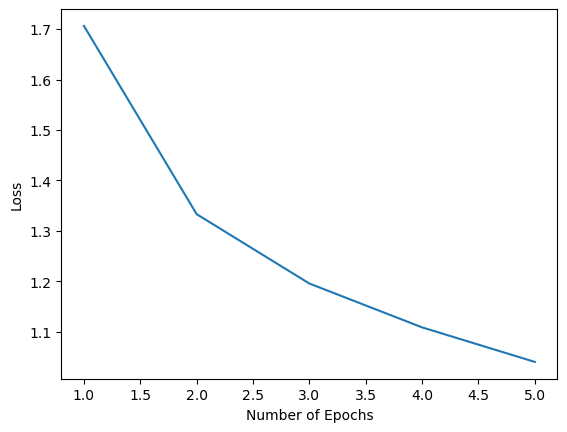

In [11]:
import matplotlib.pyplot as plt

def draw(x, y, xlabel, ylabel, image):
    plt.plot(x, y)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.savefig(image)
    plt.show()

save_image = './save_image/LossEpoch.png'
draw(count, losses, 'Number of Epochs', 'Loss', save_image)

请在报告中附上训练过程中损失函数的变化。训练集上的损失越小，说明模型的效果就越好吗？

# Task2: 加入正则化

- $L_2$正则化：请查阅Pytorch[有关SGD优化器的文档](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#sgd)或其它网络资料，修改`3. 模型训练与测试过程`中的代码，尝试为模型的损失函数加入一项$L_2$损失，并在报告中说明你所做的修改。
- Dropout正则化：请查阅Pytorch[有关Dropout层的文档](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html#dropout)或其它网络资料，修改`2. 定义用于分类的网络结构`中的代码，在**第一个线性层和第二个线性层之间**加入一个Dropout层，并在报告中说明你所做的修改。
- 在报告中简述两种正则化方法的基本原理。

In [12]:
# TODO: 在Dropout_Net中加入dropout层
class Dropout_Net(nn.Module):
    def __init__(self):
        # nn.Module子类的函数必须在构造函数中执行父类的构造函数
        super(Dropout_Net, self).__init__()

        # 卷积层 '3'表示输入图片为单通道, '6'表示输出通道数，'5'表示卷积核为5*5
        self.conv1 = nn.Conv2d(3, 6, 5) 
        # 卷积层
        self.conv2 = nn.Conv2d(6, 16, 5) 
        # 仿射层/全连接层，y = Wx + b
        self.fc1 = nn.Linear(16*5*5, 120) 
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.dropout = nn.Dropout(p=0.1) # Dropout率为0.1

    def forward(self, x): 
        # 卷积 -> 激活 -> 池化        
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = x.view(x.size()[0], -1) 
        x = F.relu(self.fc1(x))
        x = self.dropout(x) # Dropout
        x = F.relu(self.fc2(x))
        x = self.fc3(x)        
        return x
    
net = Dropout_Net()

In [13]:
# TODO: 在这里重新定义optimizer，加入L2正则化项
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9, weight_decay=0.0001) # 使用SGD（随机梯度下降）优化 # L2正则化

# 使用新定义的网络和优化器进行训练与测试
train(trainloader, net, num_epochs, criterion, optimizer, save_path)
predict(testloader, net)

epoch 1: batch 12500 loss: 1.720
epoch 2: batch 12500 loss: 1.353
epoch 3: batch 12500 loss: 1.218
epoch 4: batch 12500 loss: 1.139
epoch 5: batch 12500 loss: 1.080
Finished Training
测试集中的准确率为: 59 %


tensor(0.5908)

# Task3: 调整参数
在`3. 模型训练与测试过程`部分中，我们定义了一些超参数（如`num_epoch`、优化器的`lr`）。调节这些参数，观察损失函数以及模型在测试集上的性能变化，在报告中简要说明这些指标的变化，尝试分析这些超参数对整个模型的影响。

epoch 1: batch 12500 loss: 1.032
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.992
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.961
Finished Training
测试集中的准确率为: 59 %
epoch 1: batch 12500 loss: 0.933
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.909
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.885
Finished Training
测试集中的准确率为: 59 %
epoch 1: batch 12500 loss: 0.870
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.854
Finished Training
测试集中的准确率为: 61 %
epoch 1: batch 12500 loss: 0.832
Finished Training
测试集中的准确率为: 61 %
epoch 1: batch 12500 loss: 0.815
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.805
Finished Training
测试集中的准确率为: 59 %
epoch 1: batch 12500 loss: 0.795
Finished Training
测试集中的准确率为: 61 %
epoch 1: batch 12500 loss: 0.785
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.775
Finished Training
测试集中的准确率为: 60 %
epoch 1: batch 12500 loss: 0.762
Finished Training
测试集中的准确率为: 

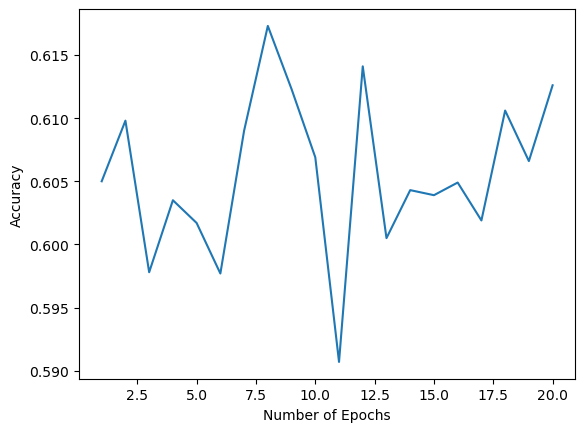

epoch 1: batch 12500 loss: 0.629
epoch 2: batch 12500 loss: 0.631
epoch 3: batch 12500 loss: 0.632
epoch 4: batch 12500 loss: 0.629
epoch 5: batch 12500 loss: 0.635
Finished Training
测试集中的准确率为: 61 %
epoch 1: batch 12500 loss: 0.630
epoch 2: batch 12500 loss: 0.632
epoch 3: batch 12500 loss: 0.624
epoch 4: batch 12500 loss: 0.622
epoch 5: batch 12500 loss: 0.619
Finished Training
测试集中的准确率为: 61 %
epoch 1: batch 12500 loss: 0.612
epoch 2: batch 12500 loss: 0.599
epoch 3: batch 12500 loss: 0.591
epoch 4: batch 12500 loss: 0.586
epoch 5: batch 12500 loss: 0.579
Finished Training
测试集中的准确率为: 61 %
epoch 1: batch 12500 loss: 0.558
epoch 2: batch 12500 loss: 0.532
epoch 3: batch 12500 loss: 0.520
epoch 4: batch 12500 loss: 0.507
epoch 5: batch 12500 loss: 0.498
Finished Training
测试集中的准确率为: 63 %
epoch 1: batch 12500 loss: 0.497
epoch 2: batch 12500 loss: 0.471
epoch 3: batch 12500 loss: 0.453
epoch 4: batch 12500 loss: 0.436
epoch 5: batch 12500 loss: 0.427
Finished Training
测试集中的准确率为: 62 %
epoch

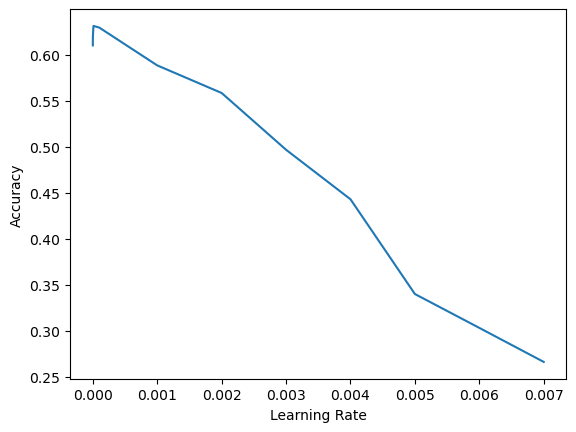

epoch 1: batch 12500 loss: 1.763
epoch 2: batch 12500 loss: 1.656
epoch 3: batch 12500 loss: 1.607
epoch 4: batch 12500 loss: 1.554
epoch 5: batch 12500 loss: 1.517
Finished Training
测试集中的准确率为: 42 %
epoch 1: batch 12500 loss: 1.493
epoch 2: batch 12500 loss: 1.465
epoch 3: batch 12500 loss: 1.440
epoch 4: batch 12500 loss: 1.422
epoch 5: batch 12500 loss: 1.402
Finished Training
测试集中的准确率为: 45 %
epoch 1: batch 12500 loss: 1.388
epoch 2: batch 12500 loss: 1.368
epoch 3: batch 12500 loss: 1.348
epoch 4: batch 12500 loss: 1.333
epoch 5: batch 12500 loss: 1.315
Finished Training
测试集中的准确率为: 47 %
epoch 1: batch 12500 loss: 1.305
epoch 2: batch 12500 loss: 1.282
epoch 3: batch 12500 loss: 1.267
epoch 4: batch 12500 loss: 1.251
epoch 5: batch 12500 loss: 1.232
Finished Training
测试集中的准确率为: 50 %
epoch 1: batch 12500 loss: 1.229
epoch 2: batch 12500 loss: 1.208
epoch 3: batch 12500 loss: 1.194
epoch 4: batch 12500 loss: 1.173
epoch 5: batch 12500 loss: 1.152
Finished Training
测试集中的准确率为: 51 %
epoch

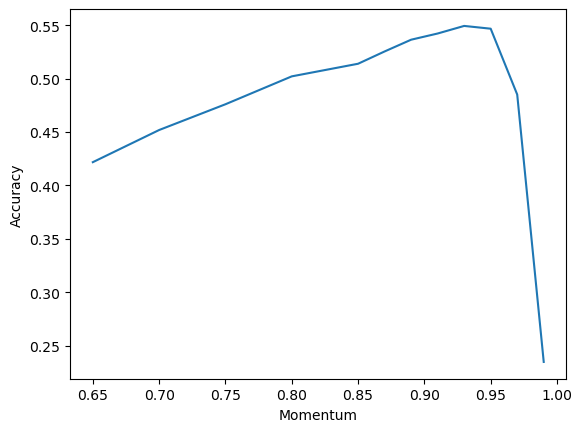

epoch 1: batch 12500 loss: 1.901
epoch 2: batch 12500 loss: 1.851
epoch 3: batch 12500 loss: 1.806
epoch 4: batch 12500 loss: 1.758
epoch 5: batch 12500 loss: 1.717
Finished Training
测试集中的准确率为: 36 %
epoch 1: batch 12500 loss: 1.682
epoch 2: batch 12500 loss: 1.651
epoch 3: batch 12500 loss: 1.625
epoch 4: batch 12500 loss: 1.607
epoch 5: batch 12500 loss: 1.587
Finished Training
测试集中的准确率为: 38 %
epoch 1: batch 12500 loss: 1.567
epoch 2: batch 12500 loss: 1.551
epoch 3: batch 12500 loss: 1.537
epoch 4: batch 12500 loss: 1.524
epoch 5: batch 12500 loss: 1.508
Finished Training
测试集中的准确率为: 40 %
epoch 1: batch 12500 loss: 1.493
epoch 2: batch 12500 loss: 1.476
epoch 3: batch 12500 loss: 1.464
epoch 4: batch 12500 loss: 1.453
epoch 5: batch 12500 loss: 1.440
Finished Training
测试集中的准确率为: 41 %
epoch 1: batch 12500 loss: 1.431
epoch 2: batch 12500 loss: 1.417
epoch 3: batch 12500 loss: 1.409
epoch 4: batch 12500 loss: 1.395
epoch 5: batch 12500 loss: 1.383
Finished Training
测试集中的准确率为: 43 %
epoch

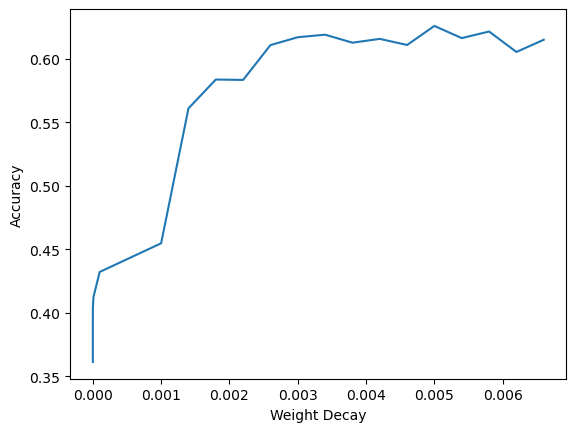

epoch 1: batch 12500 loss: 0.899
epoch 2: batch 12500 loss: 0.851
epoch 3: batch 12500 loss: 0.829
epoch 4: batch 12500 loss: 0.810
epoch 5: batch 12500 loss: 0.793
Finished Training
测试集中的准确率为: 67 %


tensor(0.6787)

In [14]:
# TODO: 在这里修改参数，重新进行训练和测试，并记录数据

# 修改num_epochs
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9, weight_decay=0.0001)
num_epochs = 1
count_epochs = []
accuracies = []
for n in range(20):
    train(trainloader, net, num_epochs, criterion, optimizer, save_path)
    count_epochs.append(n + 1)
    accuracies.append(predict(testloader, net))
save_image = './save_image/AccuracyEpoch.png'
draw(count_epochs, accuracies, 'Number of Epochs', 'Accuracy', save_image)

# 修改lr
num_epochs = 5
lr_track = 0.000000001 # 调整学习率
lrs = []
accuracies = []
for l in range(12):
    if lr_track < 0.0001:
        lr_track *= 10
    elif lr_track < 0.001:
        lr_track += 0.0003
    else:
        lr_track += 0.001
    optimizer = optim.SGD(net.parameters(), lr=lr_track, momentum=0.9, weight_decay=0.0001)
    train(trainloader, net, num_epochs, criterion, optimizer, save_path)
    lrs.append(lr_track)
    accuracies.append(predict(testloader, net))
save_image = './save_image/AccuracyLearningrate.png'
draw(lrs, accuracies, 'Learning Rate', 'Accuracy', save_image)

# 修改momentum
num_epochs = 5
momentum_track = 0.6 # 调整动量
momentums = []
accuracies = []
for m in range(12):
    if momentum_track < 0.85:
        momentum_track += 0.05
    else:
        momentum_track += 0.02
    optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=momentum_track, weight_decay=0.0001)
    train(trainloader, net, num_epochs, criterion, optimizer, save_path)
    momentums.append(momentum_track)
    accuracies.append(predict(testloader, net))
save_image = './save_image/AccuracyMomentum.png'
draw(momentums, accuracies, 'Momentum', 'Accuracy', save_image)

# 修改weight_decay
num_epochs = 5
weight_decay_track = 0.000000001 # 调整权重衰减
weight_decays = []
accuracies = []
for w in range(20):
    if weight_decay_track < 0.0001:
        weight_decay_track *= 10
    else:
        weight_decay_track += 0.0004
    optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9, weight_decay=weight_decay_track)
    train(trainloader, net, num_epochs, criterion, optimizer, save_path)
    weight_decays.append(weight_decay_track)
    accuracies.append(predict(testloader, net))
save_image = './save_image/AccuracyWeightdecay.png'
draw(weight_decays, accuracies, 'Weight Decay', 'Accuracy', save_image)

# 调整到最优参数附近
optimizer = optim.SGD(net.parameters(), lr=0.0001, momentum=0.9, weight_decay=0.002)
num_epochs = 5
train(trainloader, net, num_epochs, criterion, optimizer, save_path)
predict(testloader, net)

# Task4: 实现自己的网络
查阅资料（参考：[动手学深度学习](https://zh.d2l.ai/chapter_convolutional-modern/index.html)以及[`torchvision`的模型源码](https://github.com/pytorch/vision/tree/main/torchvision/models)），修改`2. 定义用于分类的网络结构`中的代码，实现一种现代卷积神经网络。与最基础的LeNet相比，你实现的神经网络在性能、训练时间上有何差异？

In [ ]:
# TODO: 参考2.中Net的实现，设计自己的网络，进行训练和测试，并记录数据
from torchvision import datasets
from torch.utils.data import DataLoader

# AlexNet
class AlexNet(nn.Module):
    def __init__(self, num_classes=10):
        super(AlexNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 192, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

num_epochs = 8
batch_size = 64

# CIFAR-10
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # 归一化
])

train_dataset = datasets.CIFAR10(root='./dataset', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./dataset', train=False, download=True, transform=transform)

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

model = AlexNet(num_classes=10)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)

# 训练并预测
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f'Epoch {epoch+1}, Loss: {running_loss / len(train_loader)}')

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f'测试集中的准确率为： {100 * correct / total}%')

Files already downloaded and verified
Files already downloaded and verified
Epoch 1, Loss: 1.8927264501676535
测试集中的准确率为： 40.69%
Epoch 2, Loss: 1.4844435258289737
测试集中的准确率为： 54.5%
Epoch 3, Loss: 1.231605243652373
测试集中的准确率为： 63.1%
Epoch 4, Loss: 1.062228541544941
测试集中的准确率为： 66.13%
Epoch 5, Loss: 0.9425885851883218
测试集中的准确率为： 66.92%
Epoch 6, Loss: 0.8520079183837642
测试集中的准确率为： 72.47%
Epoch 7, Loss: 0.7756859962745091
测试集中的准确率为： 71.39%
Epoch 8, Loss: 0.7132991967375016
测试集中的准确率为： 73.9%
Epoch 9, Loss: 0.6510673757937863
测试集中的准确率为： 76.0%
Epoch 10, Loss: 0.6033345099605257
测试集中的准确率为： 74.93%
